# Лабораторная работа №4

Номер по списку: **10**, ПК: **10**, группа: **2**.

Варианты таблиц выбираются по кругу: (номер−1) % число строк + 1. Для ЛР3–4 N=ПК+группа; N не является номером по списку.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats, special
import pywt
plt.rcParams.update({'figure.figsize': (12,4), 'figure.dpi': 100,
                     'axes.grid': True, 'grid.alpha': .25})
number=10; pc=10; group=2
rng=np.random.default_rng(1010)


## Нестационарный сигнал
$N=ПК+2$, $L=N\bmod3$. При L=0 формируем ЛЧМ от $(1000+20N)$ до $(1400+20N)$ кГц. Для ЛЧМ принято $t_и=40$ мкс: видеоимпульс N нс из ЛР3 короче одного периода мегагерцевой несущей и не позволяет показать перестройку. Это явное моделирующее допущение, унаследованное из выбранного ранее шаблона.
При L=2 формируем ППРЧ: пять каналов с шагом $3f_m$, длительность чипа $2/f_m$; несущая и частота модуляции взяты из ЛР3. Между чипами введены короткие паузы 4% длительности чипа для исследования временного разрешения.
Структура: **генератор частот → формирование фазы и огибающей → сигнал → STFT / CWT**.
Для STFT $\Delta f\approx f_s/N_w$, шаг $H=N_w-\mathrm{noverlap}$. Длинное окно улучшает частотное разрешение и размывает паузы; уменьшение шага делает временную сетку плотнее, но не улучшает собственное разрешение окна.

ЛЧМ: 1240.0 → 1640.0 кГц; tи= 40.0 мкс


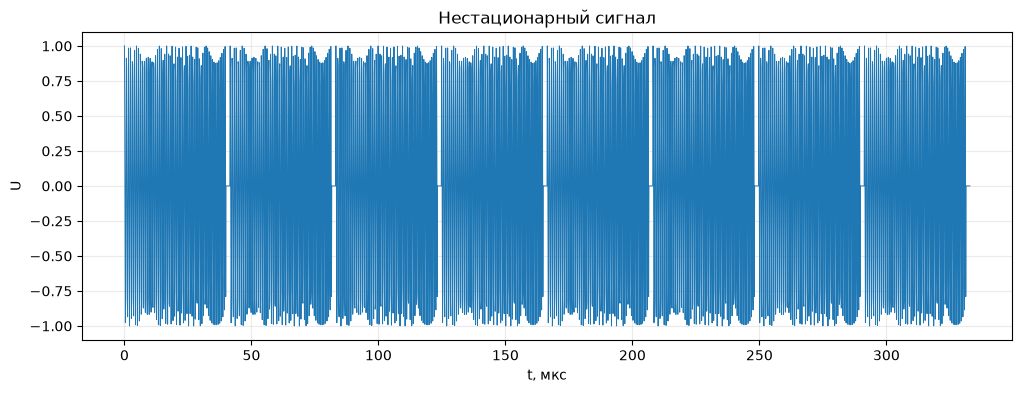

Пауза: 13 отсчётов = 1.625 мкс


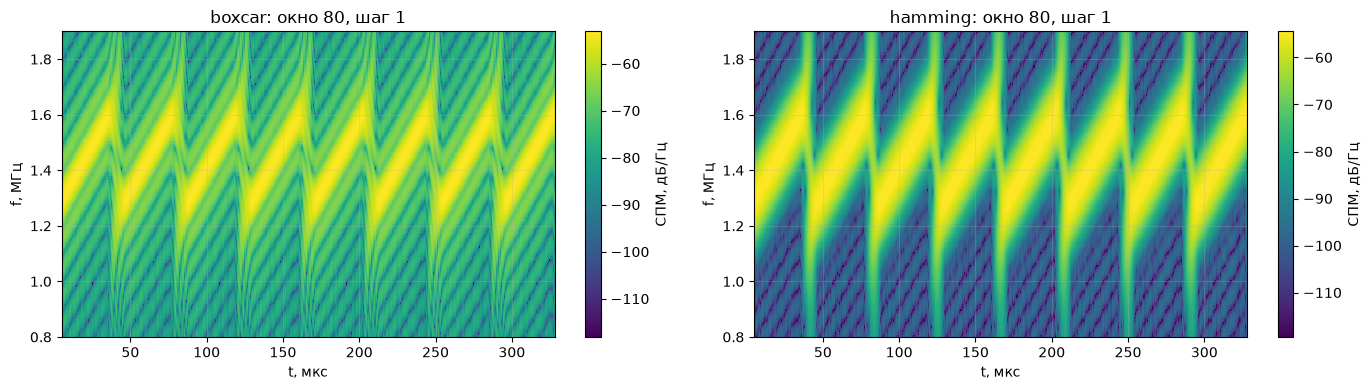

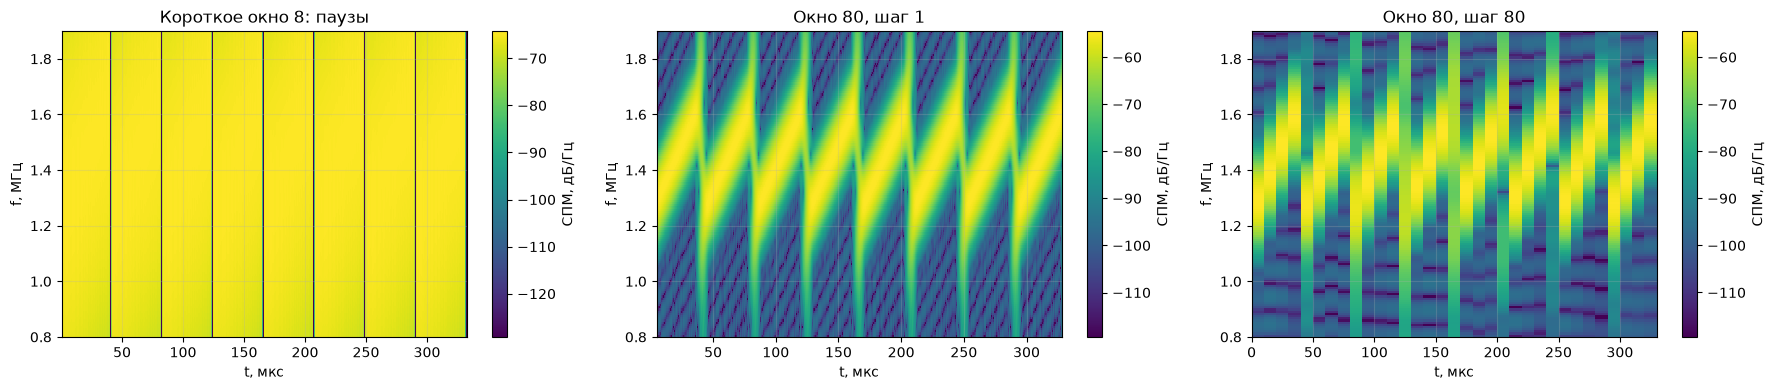

Количество временных окон: шаг 1 / шаг Nw: 2585 33


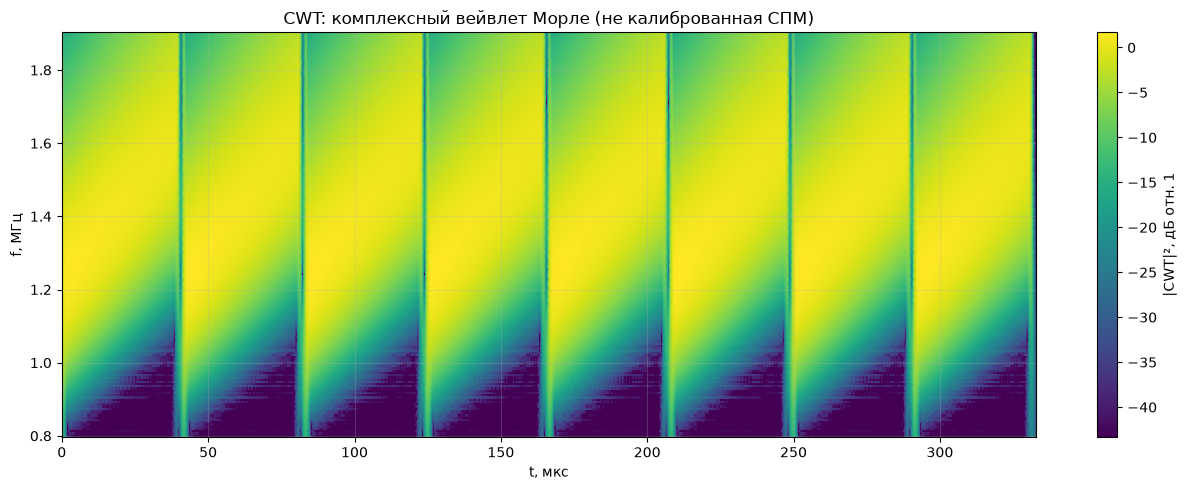

In [2]:
N=pc+group; M=N%10; L=N%3
chips=8
if L==0:
    fs=8e6; ti=40e-6; gap=.04*ti; f0=(1000+20*N)*1e3; f1=(1400+20*N)*1e3
    unit=int(round(ti*fs)); pause=int(round(gap*fs)); x=np.zeros(chips*(unit+pause))
    local=np.arange(unit)/fs
    chip=np.cos(2*np.pi*(f0*local+(f1-f0)*local**2/(2*ti)))
    for j in range(chips): x[j*(unit+pause):j*(unit+pause)+unit]=chip
    short=8; long=80; flim=(.8,1.9)
    print('ЛЧМ:',f0/1e3,'→',f1/1e3,'кГц; tи=',ti*1e6,'мкс')
else:
    fc=10*N*1e6; fm=(N//10+M)*1e6; ti=2/fm; gap=.04*ti; fs=400e6
    channels=fc+np.arange(-2,3)*3*fm
    unit=int(round(ti*fs)); pause=int(round(gap*fs)); x=np.zeros(chips*(unit+pause))
    order=rng.permutation(5).tolist()+rng.integers(0,5,size=chips-5).tolist()
    local=np.arange(unit)/fs
    for j,k in enumerate(order):
        x[j*(unit+pause):j*(unit+pause)+unit]=np.cos(2*np.pi*channels[k]*local)
    short=8; long=128; flim=(0,100)
    print('Каналы, МГц:',channels/1e6,'порядок:',order,'длительность чипа, мкс:',ti*1e6)
t=np.arange(len(x))/fs
fig,ax=plt.subplots(); ax.plot(t*1e6,x,lw=.7); ax.set(xlabel='t, мкс',ylabel='U',title='Нестационарный сигнал'); plt.show()
print('Пауза:',pause,'отсчётов =',pause/fs*1e6,'мкс')
def spec(ax,window,nwin,hop,title):
    f,ts,p=signal.spectrogram(x,fs=fs,window=window,nperseg=nwin,noverlap=nwin-hop,nfft=max(1024,nwin),detrend=False,scaling='density',mode='psd')
    z=10*np.log10(np.maximum(p,1e-20))
    im=ax.pcolormesh(ts*1e6,f/1e6,z,shading='auto',vmin=z.max()-65,vmax=z.max())
    ax.set(xlabel='t, мкс',ylabel='f, МГц',ylim=flim,title=title)
    plt.colorbar(im,ax=ax,label='СПМ, дБ/Гц')
    return len(ts)
fig,axs=plt.subplots(1,2,figsize=(14,4))
for ax,win in zip(axs,['boxcar','hamming']):
    spec(ax,win,long,1,f'{win}: окно {long}, шаг 1')
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,3,figsize=(18,4))
spec(axs[0],'hamming',short,1,f'Короткое окно {short}: паузы')
columns1=spec(axs[1],'hamming',long,1,f'Окно {long}, шаг 1')
columns2=spec(axs[2],'hamming',long,long,f'Окно {long}, шаг {long}')
plt.tight_layout(); plt.show()
print('Количество временных окон: шаг 1 / шаг Nw:',columns1,columns2)
# Непрерывное вейвлет-преобразование, физическая ось частот.
wavelet='cmor1.5-1.0'
freqs=np.linspace(max(flim[0],.1),flim[1],180)*1e6
scales=pywt.central_frequency(wavelet)*fs/freqs
coef,fw=pywt.cwt(x,scales,wavelet,sampling_period=1/fs,method='fft')
power=np.abs(coef)**2
fig,ax=plt.subplots(figsize=(13,5))
z=10*np.log10(np.maximum(power,1e-15))
im=ax.pcolormesh(t*1e6,fw/1e6,z,shading='auto',vmin=z.max()-45,vmax=z.max())
ax.set(xlabel='t, мкс',ylabel='f, МГц',title='CWT: комплексный вейвлет Морле (не калиброванная СПМ)')
plt.colorbar(im,ax=ax,label='|CWT|², дБ отн. 1'); plt.tight_layout(); plt.show()
assert np.all(np.isfinite(coef))

## Выводы
Прямоугольное окно даёт узкий главный лепесток, но сильнее растекается по частоте. Хэмминг подавляет боковые лепестки, расширяя основной. Короткое окно выделяет паузы, но размывает частоты; длинное лучше разделяет каналы или показывает наклон ЛЧМ, зато сглаживает моменты переключения. Шаг 1 даёт более плотную картину, а шаг в окно — меньше временных столбцов при том же частотном разрешении. Нулевое дополнение БПФ интерполирует спектр и не заменяет увеличение окна.
CWT меняет временное разрешение с частотой: на высоких частотах эффективное окно короче. Края записи подвержены краевым эффектам, поэтому яркость у границ не следует интерпретировать как отдельные сигналы. Значения |CWT|² не равны калиброванной СПМ STFT.